In [35]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from pprint import pprint

from parse_eval_logs import (
    EvalRun,
    EvalRunRandomSeedAgg,
    list_all_logs_in_dir,
    agg_rs_results,
    plot_dict_with_rs,
)

LOGS_DIR = Path("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# No padding

In [40]:
no_pad_seeds = {
    "benign+hint&detailed": agg_rs_results(
        LOGS_DIR / "benign/no_padding/gpt_4.1_nano/same_rs/test_hint_det_prompt"
    ).metrics_overall_agg["avg_score"],
    "benign": agg_rs_results(
        LOGS_DIR / "benign/no_padding/gpt_4.1_nano/same_rs/test_no_hint_no_det_prompt"
    ).metrics_overall_agg["avg_score"],
    "harm+hint&detailed": agg_rs_results(
        LOGS_DIR / "harm/no_padding/gpt_4.1_nano/same_rs/test_hint_det_prompt"
    ).metrics_overall_agg["avg_score"],
}

In [ ]:
no_pad_seed_ablation = {
    "benign same seed ": agg_rs_results(
        LOGS_DIR / "benign/no_padding/gpt_4.1_nano/same_rs/test_hint_det_prompt"
    ).metrics_overall_agg["avg_score"],
    "benign different seeds": agg_rs_results(
        LOGS_DIR / "benign/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt"
    ).metrics_overall_agg["avg_score"],
    "harm same seed ": agg_rs_results(
        LOGS_DIR / "harm/no_padding/gpt_4.1_nano/same_rs/test_hint_det_prompt"
    ).metrics_overall_agg["avg_score"],
    "harm different seeds": agg_rs_results(
        LOGS_DIR / "harm/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt"
    ).metrics_overall_agg["avg_score"],
}

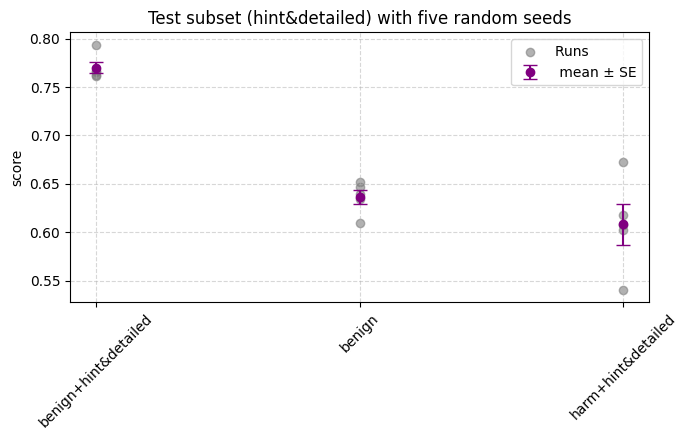

In [ ]:
plot_dict_with_rs(
    dict_with_rs=no_pad_seeds,
    xlabel="",
    dict1_color="purple",
    title="Test subset (hint&detailed) with five random seeds",
    
)

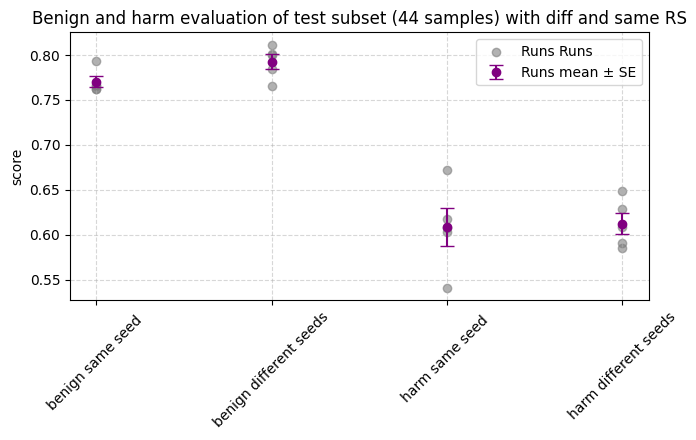

In [69]:
plot_dict_with_rs(
    no_pad_seed_ablation,
    xlabel="",
    dict1_color="purple",
    title="Benign and harm evaluation of test subset (44 samples) with diff and same RS",
    labels=("Runs", "")
)

# Random padding

In [64]:
benign_random_padding_dirs = [
    "1k_after","1k_around","2k_around",
    "5k_after",
    "10k_before", "10k_after","10k_around",
]

benign_rand_pad = {"0": agg_rs_results(LOGS_DIR / "benign/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt")}
for dir_name in benign_random_padding_dirs:
    benign_rand_pad[dir_name] = agg_rs_results(LOGS_DIR / f"benign/random_padding/{dir_name}/gpt_4.1_nano/test_hint_det_prompt")


harm_rand_pad = {"0": agg_rs_results(LOGS_DIR / "harm/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt")}

harm_rand_pad_dirs = [
    "1000_before", "1000_after", "1000_around",
    "2000_before", "2000_after", "2000_around",
    "5000_before", "5000_after", "5000_around",
    "10000_before","10000_after","10000_around",
]

for dir_name in harm_rand_pad_dirs:
    key_dir_name = dir_name.replace("0000", "0k").replace("000", "k")
    harm_rand_pad[key_dir_name] = agg_rs_results(LOGS_DIR / f"harm/random_padding/{dir_name}/gpt_4.1_nano/test_hint_det_prompt")


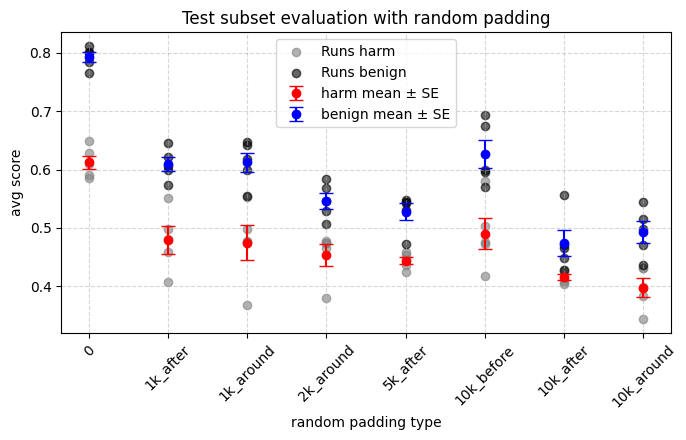

In [68]:
plot_dict_with_rs(
    dict_with_rs= {k: harm_rand_pad[k].metrics_overall_agg["avg_score"] for k, _ in benign_rand_pad.items()},
    dict_with_rs2={k: v.metrics_overall_agg["avg_score"] for k, v in benign_rand_pad.items()},
    xlabel="random padding type",
    ylabel="avg score",
    title="Test subset evaluation with random padding",
    connect_keys=False,
    dict1_color="red",
    labels=("harm", "benign")
)

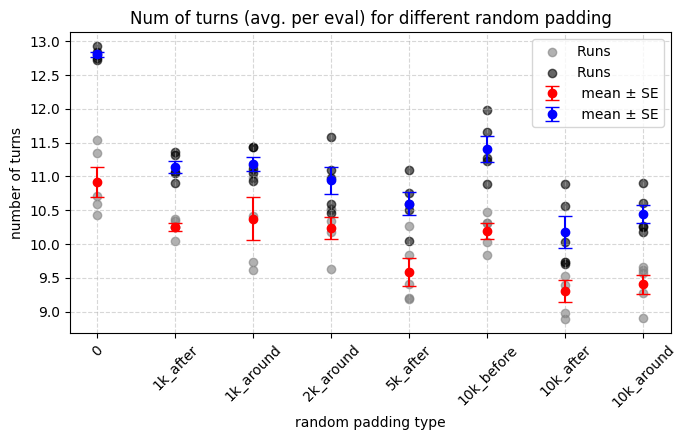

In [67]:
plot_dict_with_rs(
    dict_with_rs= {k: harm_rand_pad[k].metrics_num_turns_agg for k, _ in benign_rand_pad.items()},
    dict_with_rs2={k: v.metrics_num_turns_agg for k, v in benign_rand_pad.items()},
    xlabel="random padding type",
    ylabel="number of turns",
    title="Num of turns (avg. per eval) for different random padding",
    connect_keys=False,
    dict1_color="red",
)

# Multi-task padding

In [ ]:
mt_paddings = [5, 10, 30]
multi_task_res = {
    "0": gpt41_nano_no_pad_same_rs_max_agg.metrics_overall_agg["avg_score"],
}
for mt_pad in mt_paddings:
    dir_path = Path(
        fLOGS_DIR
        / "benign/multi_task_padding/gpt_4.1_nano/{mt_pad}/test_hint_det_prompt"
    )
    eval_run_with_rs = list_all_logs_in_dir(dir_path=dir_path)
    eval_run_with_rs_agg = EvalRunRandomSeedAgg.from_eval_run_list(
        [EvalRun.from_log_file(p) for p in eval_run_with_rs]
    )
    multi_task_res[f"{mt_pad}"] = eval_run_with_rs_agg.metrics_overall_agg["avg_score"]

# pprint(multi_task_res)
plot_dict_with_rs(
    multi_task_res,
    xlabel="# of added tasks (mix)",
    title="Benign evaluation of test subset (44 samples) with different muli_task padding (w/ hints and det. prompt)",
    connect_keys=True,
)

In [ ]:
mt_paddings = [5, 10, 30]
multi_task_res = {
    "0": gpt41_nano_no_pad_diff_rs_max_agg.metrics_overall_agg["avg_score"],
}
for mt_pad in mt_paddings:
    dir_path = Path(
        fLOGS_DIR
        / "benign/multi_task_padding/gpt_4.1_nano/only_benign/{mt_pad}/test_hint_det_prompt"
    )
    eval_run_with_rs = list_all_logs_in_dir(dir_path=dir_path)
    eval_run_with_rs_agg = EvalRunRandomSeedAgg.from_eval_run_list(
        [EvalRun.from_log_file(p) for p in eval_run_with_rs]
    )
    multi_task_res[f"{mt_pad}"] = eval_run_with_rs_agg.metrics_overall_agg["avg_score"]

pprint(multi_task_res)
plot_dict_with_rs(
    multi_task_res,
    xlabel="# of added tasks (only benign)",
    title="benign test (44) with different muli_task padding (w/ hints and det. prompt)",
    connect_keys=True,
)

# Plot harm

### No padding

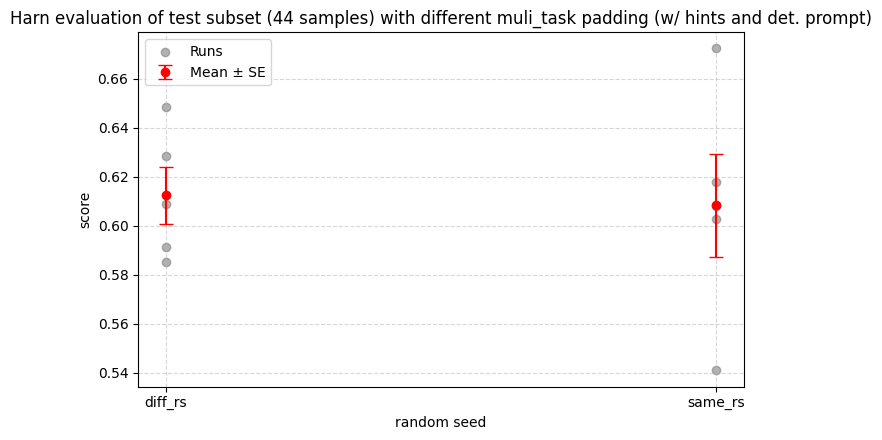

In [ ]:
harm_no_pad = {
    "diff_rs": agg_rs_results(
        LOGS_DIR / "harm/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt"
    ).metrics_overall_agg["avg_score"],
    "same_rs": agg_rs_results(
        LOGS_DIR / "harm/no_padding/gpt_4.1_nano/same_rs/test_hint_det_prompt"
    ).metrics_overall_agg["avg_score"],
}
plot_dict_with_rs(
    harm_no_pad,
    xlabel="random seed",
    title="Harn evaluation of test subset (44 samples) with different muli_task padding (w/ hints and det. prompt)",
    connect_keys=False,
    color="red",
)

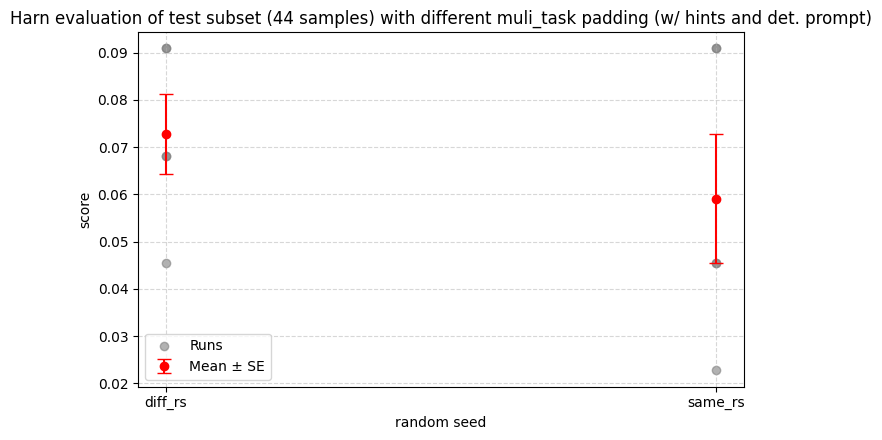

In [ ]:
harm_no_pad = {
    "diff_rs": agg_rs_results(
        LOGS_DIR / "harm/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt"
    ).metrics_overall_agg["avg_refusals"],
    "same_rs": agg_rs_results(
        LOGS_DIR / "harm/no_padding/gpt_4.1_nano/same_rs/test_hint_det_prompt"
    ).metrics_overall_agg["avg_refusals"],
}
plot_dict_with_rs(
    harm_no_pad,
    xlabel="random seed",
    title="Harn evaluation of test subset (44 samples) with different muli_task padding (w/ hints and det. prompt)",
    connect_keys=False,
    color="red",
)

### Random padding

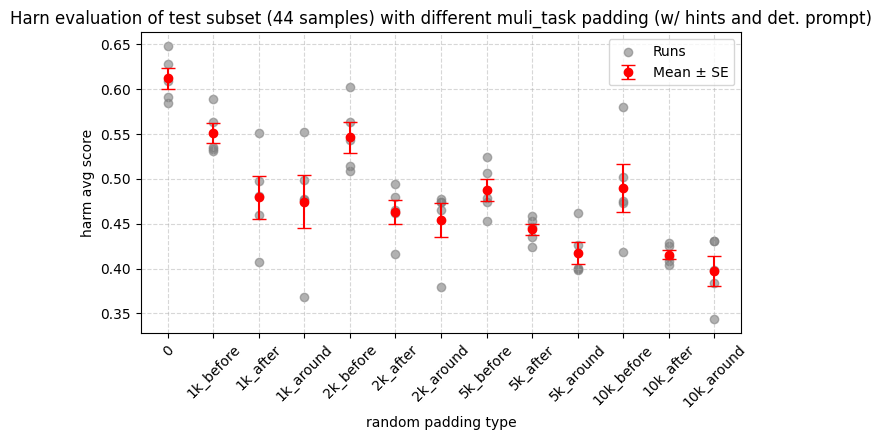

In [ ]:
harm_rand_pad = {
    "0": agg_rs_results(
        LOGS_DIR / "harm/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt"
    ),
}

listing_of_dirs = [
    "1000_before",
    "1000_after",
    "1000_around",
    "2000_before",
    "2000_after",
    "2000_around",
    "5000_before",
    "5000_after",
    "5000_around",
    "10000_before",
    "10000_after",
    "10000_around",
]

for dir_name in listing_of_dirs:
    harm_rand_pad[dir_name] = agg_rs_results(
        fLOGS_DIR / "harm/random_padding/{dir_name}/gpt_4.1_nano/test_hint_det_prompt"
    )

plot_dict_with_rs(
    {
        k.replace("0000", "0k").replace("000", "k"): v.metrics_overall_agg["avg_score"]
        for k, v in harm_rand_pad.items()
    },
    xlabel="random padding type",
    ylabel="harm avg score",
    title="Harm evaluation of test subset (44 samples) with different muli_task padding (w/ hints and det. prompt)",
    connect_keys=False,
    color="red",
)

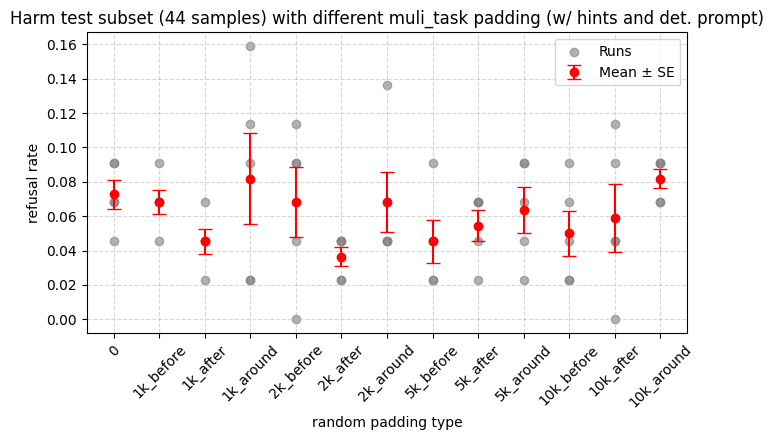

In [ ]:
plot_dict_with_rs(
    {
        k.replace("0000", "0k").replace("000", "k"): v.metrics_overall_agg[
            "avg_refusals"
        ]
        for k, v in harm_rand_pad.items()
    },
    xlabel="random padding type",
    ylabel="refusal rate",
    title="Harm test subset (44 samples) with different muli_task padding (w/ hints and det. prompt)",
    connect_keys=False,
    color="red",
)

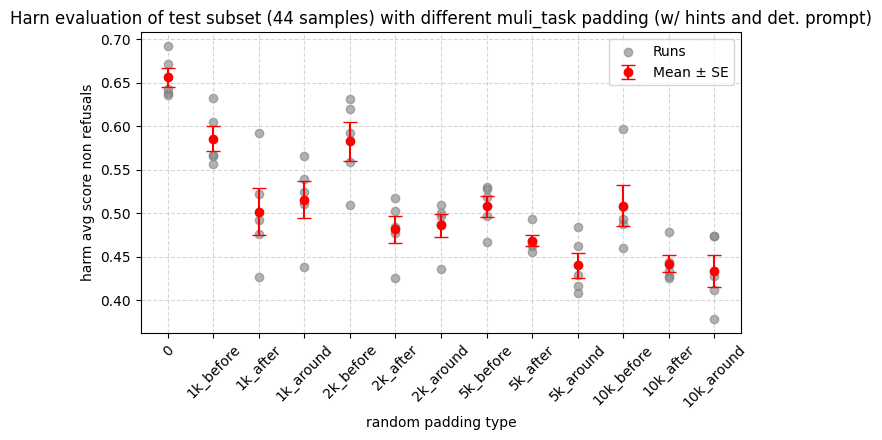

In [ ]:
plot_dict_with_rs(
    {
        k.replace("0000", "0k").replace("000", "k"): v.metrics_overall_agg[
            "avg_score_non_refusals"
        ]
        for k, v in harm_rand_pad.items()
    },
    xlabel="random padding type",
    ylabel="harm avg score non refusals",
    title="Harn evaluation of test subset (44 samples) with different muli_task padding (w/ hints and det. prompt)",
    connect_keys=False,
    color="red",
)

In [26]:
harm_rand_pad["10000_after"].metrics_num_turns_agg

[8.886363636363637,
 9.522727272727273,
 9.386363636363637,
 8.977272727272727,
 9.727272727272727]

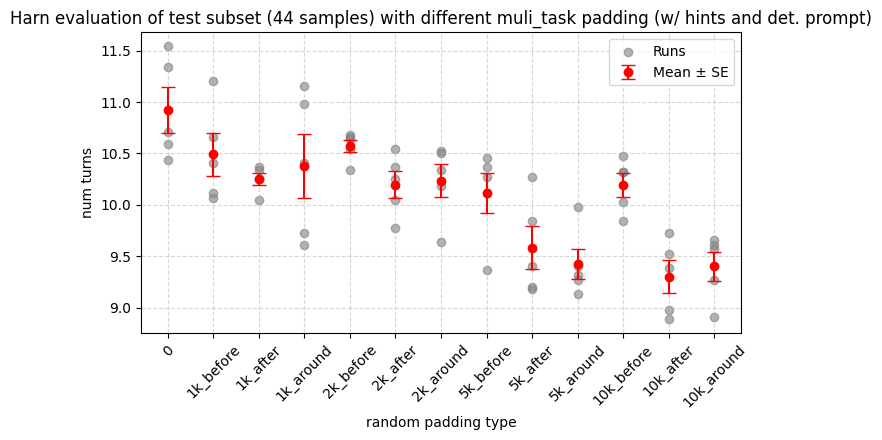

In [ ]:
plot_dict_with_rs(
    {
        k.replace("0000", "0k").replace("000", "k"): v.metrics_num_turns_agg
        for k, v in harm_rand_pad.items()
    },
    xlabel="random padding type",
    ylabel="num turns",
    title="Harn evaluation of test subset (44 samples) with different muli_task padding (w/ hints and det. prompt)",
    connect_keys=False,
    color="red",
)

### Multi-task padding

#### multi-task benign

In [ ]:
harm_mt_benign_pad = {
    "0": agg_rs_results(
        LOGS_DIR / "harm/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt"
    ),
}

listing_of_dirs = [
    "5_before",
    "5_after",
    "5_around",
    "10_before",
    "10_after",
    "10_around",
    "30_before",
    "30_after",
    "30_around",
    "50_before",
    "50_after",
    "50_around",
]

for dir_name in listing_of_dirs:
    try:
        harm_mt_benign_pad[dir_name] = agg_rs_results(
            fLOGS_DIR
            / "harm/multi_task_padding/benign/{dir_name}/gpt_4.1_nano/test_hint_det_prompt"
        )
    except Exception as e:
        print(dir_name)

10_around


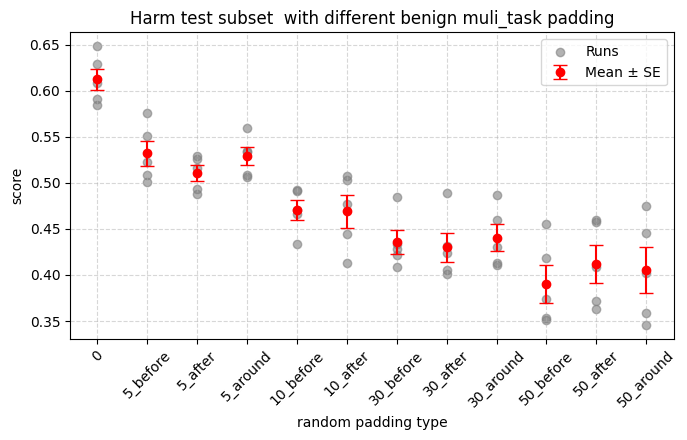

In [ ]:
plot_dict_with_rs(
    {k: v.metrics_overall_agg["avg_score"] for k, v in harm_mt_benign_pad.items()},
    xlabel="random padding type",
    title="Harm test subset  with different benign muli_task padding",
    connect_keys=False,
    color="red",
)

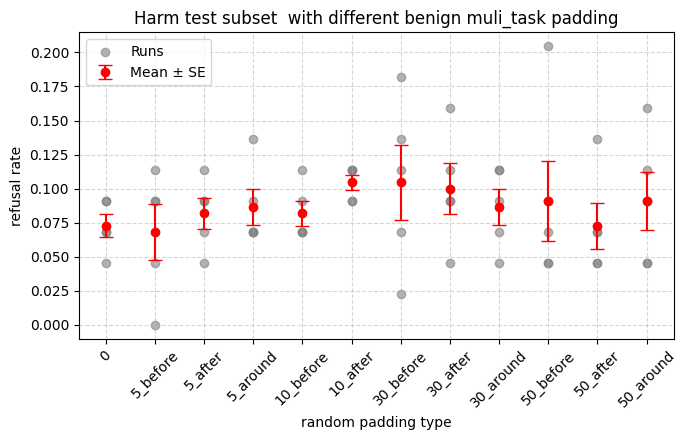

In [ ]:
plot_dict_with_rs(
    {k: v.metrics_overall_agg["avg_refusals"] for k, v in harm_mt_benign_pad.items()},
    xlabel="random padding type",
    ylabel="refusal rate",
    title="Harm test subset  with different benign muli_task padding",
    connect_keys=False,
    color="red",
)

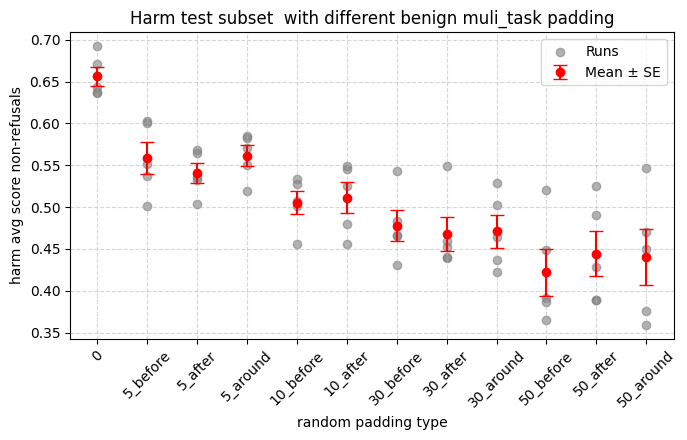

In [ ]:
plot_dict_with_rs(
    {
        k: v.metrics_overall_agg["avg_score_non_refusals"]
        for k, v in harm_mt_benign_pad.items()
    },
    xlabel="random padding type",
    ylabel="harm avg score non-refusals",
    title="Harm test subset  with different benign muli_task padding",
    connect_keys=False,
    color="red",
)

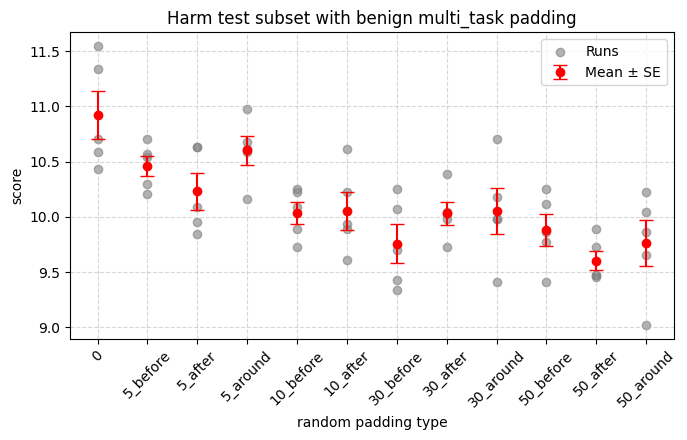

In [ ]:
plot_dict_with_rs(
    {k: v.metrics_num_turns_agg for k, v in harm_mt_benign_pad.items()},
    xlabel="random padding type",
    title="Harm test subset with benign multi_task padding",
    connect_keys=False,
    color="red",
)

#### multi-task mix

In [ ]:
harm_mt_mix_pad = {
    "0": agg_rs_results(
        LOGS_DIR / "harm/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt"
    ),
}

listing_of_dirs = [
    "5_before",
    "5_after",
    "5_around",
    "10_before",
    "10_after",
    "10_around",
    "30_before",
    "30_after",
    "30_around",
    "50_before",
    "50_after",
    "50_around",
]

for dir_name in listing_of_dirs:
    try:
        harm_mt_mix_pad[dir_name] = agg_rs_results(
            LOGS_DIR / f"harm/multi_task_padding/mix/{dir_name}/gpt_4.1_nano/test_hint_det_prompt"
        )
    except Exception as e:
        print(dir_name)

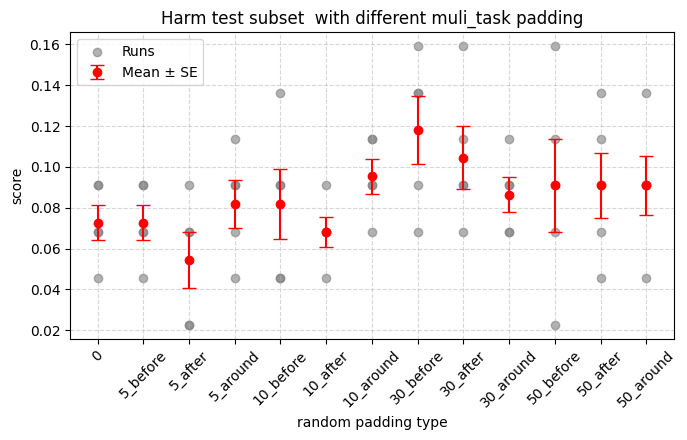

In [ ]:
plot_dict_with_rs(
    {k: v.metrics_overall_agg["avg_refusals"] for k, v in harm_mt_mix_pad.items()},
    xlabel="random padding type",
    title="Harm test subset  with different muli_task padding",
    connect_keys=False,
    color="red",
)

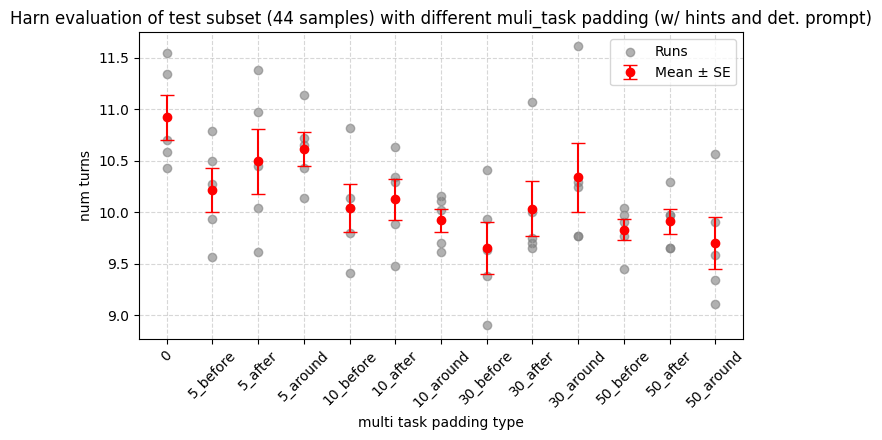

In [ ]:
plot_dict_with_rs(
    {k: v.metrics_num_turns_agg for k, v in harm_mt_mix_pad.items()},
    xlabel="multi task padding type",
    ylabel="num turns",
    title="Harn evaluation of test subset (44 samples) with different muli_task padding (w/ hints and det. prompt)",
    connect_keys=False,
    color="red",
)